# RF vs. GNN -- Summary Figures (Heatmaps & Bar Charts), including AUROC and AUPRC

Produces the summary figures from the 10-seed multi-run significance analysis:

- **Figure 1** -- 3-panel heatmap (precision / recall / F1), GNN - RF difference per architecture x class
- **Figure 2** -- Overall performance bar chart (mean +/- std across 10 runs) vs. RF's fixed value:
  accuracy, MCC, **macro AUROC and macro AUPRC** (falls back to accuracy & MCC only if no AUC file is present)
- **Figure 3** -- Standalone F1 heatmap (the "key table")
- **Figure 4** *(new)* -- Per-class **AUROC and AUPRC** heatmaps: GNN mean with the difference from RF in parentheses

**Requires** (same folder as this notebook, or update the paths below):
`FINAL_overall_ttest_vs_RF.csv`, `FINAL_per_class_ttest_vs_RF.csv` and, for the AUC panels / Figure 4,
`FINAL_auc_ttest_vs_RF.csv` (all produced by the multi-run t-test notebook).

**Colour convention (all heatmaps):** red = GNN higher than RF, blue = RF higher than GNN (difference = GNN - RF).

**Changes relative to the previous version of this notebook**
- Figure 1's footnote previously described the colours the wrong way round (it said blue = GNN higher); corrected.
- Figure 2's y-axis limits now extend automatically so that no bar or error bar is cut off (previously a bar below the
  hard-coded 0.40 floor, e.g. a low MCC, was invisible). The original limits are kept whenever nothing would be clipped.
- RF's accuracy and MCC are read from the CSV instead of being typed in, so they cannot drift from the statistics.
- Figure 2's legend moved below the axes (it overlapped bars), and its footnote now says the stars are *uncorrected* p < 0.05.
- Figure 1's panel spacing increased: the row labels (e.g. "GraphSAGE") previously overlapped the last column of the panel to their left.

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

%matplotlib inline

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "figure.facecolor": "white",
})

## 1. Load data

In [14]:
overall_path = "FINAL_overall_ttest_vs_RF.csv"
per_class_path = "FINAL_per_class_ttest_vs_RF.csv"
auc_path = "FINAL_auc_ttest_vs_RF.csv"          # optional: AUROC / AUPRC results

overall = pd.read_csv(overall_path)
per_class = pd.read_csv(per_class_path)
auc = pd.read_csv(auc_path) if os.path.exists(auc_path) else None
HAVE_AUC = auc is not None and len(auc) > 0

architectures = ["GCN", "GAT", "GINE", "GraphSAGE"]
classes = ["AA", "AI", "IA", "II"]
metrics = ["precision", "recall", "f1"]

# Random Forest's fixed (deterministic) reference values -- read from the CSV so they always match the statistics
RF_ACC = float(overall[overall.Metric == "Accuracy"].RF.iloc[0])
RF_MCC = float(overall[overall.Metric == "MCC"].RF.iloc[0])
print(f"RF reference from CSV: accuracy={RF_ACC:.3f}, MCC={RF_MCC:.3f}")

OVERALL_ALPHA = 0.05      # star threshold used in Figure 2 (uncorrected, as in the previous version)
BARS_FROM_ZERO = False    # True = start every Figure-2 bar axis at 0 (avoids visually exaggerating small differences)

# test-set class supports, used only for the AUPRC chance level (= class prevalence). Update if the split changes.
N_TEST = 523
SUPPORTS = {"AA": 64, "AI": 20, "IA": 167, "II": 272}

if HAVE_AUC:
    print("AUC results found: Figure 2 will include macro AUROC / AUPRC and Figure 4 will be produced.")
else:
    print("No FINAL_auc_ttest_vs_RF.csv found: Figure 2 will show accuracy & MCC only; Figure 4 is skipped.")

overall.head()

RF reference from CSV: accuracy=0.490, MCC=0.230
AUC results found: Figure 2 will include macro AUROC / AUPRC and Figure 4 will be produced.


,Architecture,Metric,RF,GNN_mean,GNN_std,t_stat,p_value
0,GCN,Accuracy,0.49,0.523901,0.022001,4.622595,0.001250
1,GCN,MCC,0.23,0.218763,0.030760,-1.095890,0.301584
2,GAT,Accuracy,0.49,0.482983,0.026785,-0.785948,0.452093
3,GAT,MCC,0.23,0.241178,0.028565,1.173950,0.270543
4,GINE,Accuracy,0.49,0.449522,0.056581,-2.146184,0.060411


## 2. Figure 1 — Per-class heatmap (precision / recall / F1), GNN − RF

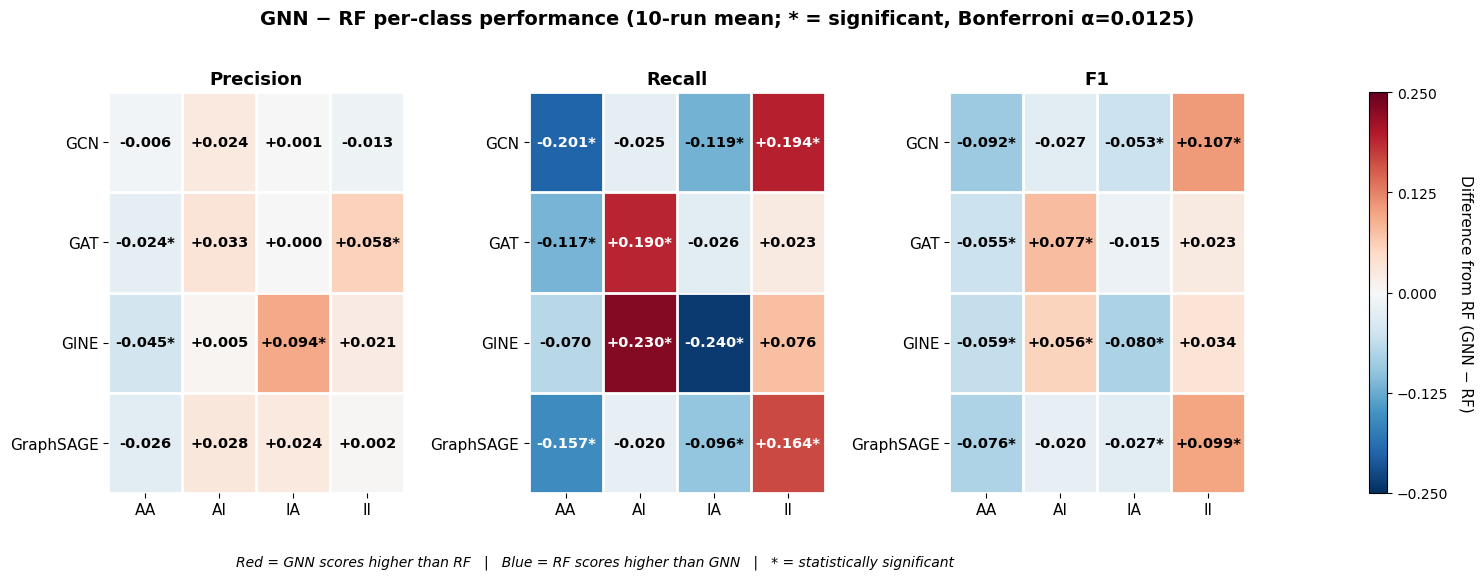

Saved: Figure1_per_class_heatmap.png


In [15]:
cmap = plt.cm.RdBu_r  # blue = GNN higher, red = RF higher
norm = TwoSlopeNorm(vmin=-0.25, vcenter=0, vmax=0.25)

# gridspec reserves a dedicated narrow column for the colorbar so it never
# overlaps the third (F1) heatmap
fig = plt.figure(figsize=(16.5, 5.2))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 0.06], wspace=0.55)  # wider gap so the row labels of one panel do not run into the previous panel
axes = [fig.add_subplot(gs[0, i]) for i in range(3)]
cax = fig.add_subplot(gs[0, 3])

im = None
for ax, metric in zip(axes, metrics):
    mat = np.zeros((len(architectures), len(classes)))
    annot = np.empty((len(architectures), len(classes)), dtype=object)
    for i, arch in enumerate(architectures):
        for j, cls in enumerate(classes):
            row = per_class[(per_class.Architecture == arch) &
                             (per_class.Class == cls) &
                             (per_class.Metric == metric)].iloc[0]
            mat[i, j] = row["diff"]
            star = "*" if row["significant_bonf"] else ""
            annot[i, j] = f"{row['diff']:+.3f}{star}"

    im = ax.imshow(mat, cmap=cmap, norm=norm, aspect="auto")
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticks(range(len(architectures)))
    ax.set_yticklabels(architectures)
    ax.set_title(metric.capitalize())

    for i in range(len(architectures)):
        for j in range(len(classes)):
            ax.text(j, i, annot[i, j], ha="center", va="center",
                     fontsize=10.5, fontweight="bold",
                     color="white" if abs(mat[i, j]) > 0.15 else "black")

    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks(np.arange(-0.5, len(classes), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(architectures), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", size=0)

cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Difference from RF (GNN \u2212 RF)", rotation=270, labelpad=18, fontsize=11)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks([-0.25, -0.125, 0, 0.125, 0.25])

fig.suptitle("GNN \u2212 RF per-class performance (10-run mean; * = significant, Bonferroni \u03b1=0.0125)",
             fontsize=14, fontweight="bold", y=1.04)
fig.text(0.42, -0.03,
         "Red = GNN scores higher than RF   |   Blue = RF scores higher than GNN   |   * = statistically significant",
         ha="center", fontsize=10, style="italic")

fig.savefig("Figure1_per_class_heatmap.png", dpi=220, bbox_inches="tight")
plt.show()
print("Saved: Figure1_per_class_heatmap.png")

## 3. Figure 2 -- Overall performance (mean +/- std across 10 runs) vs. RF

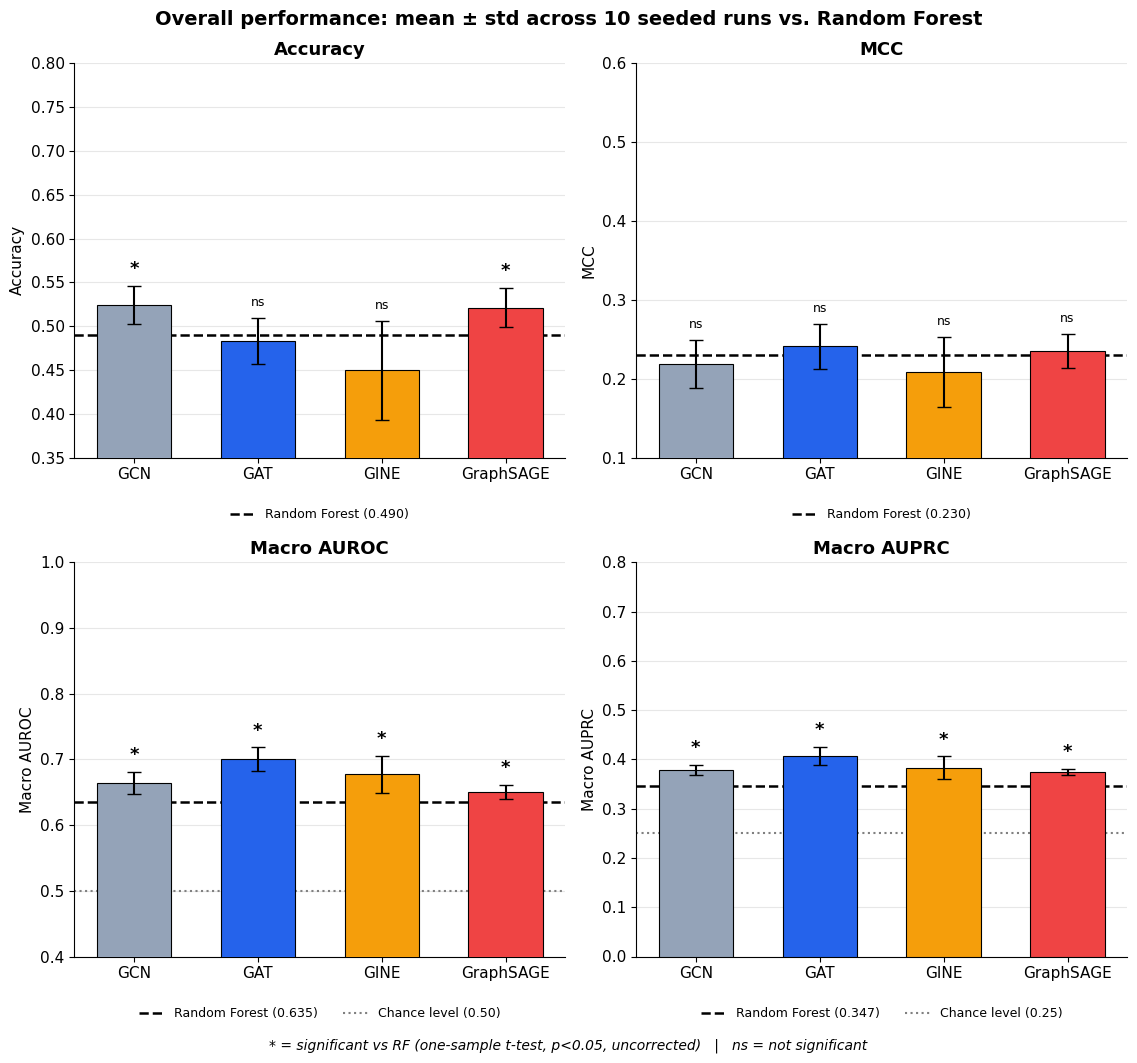

Saved: Figure2_overall_performance.png


In [16]:
colors = {"GCN": "#94a3b8", "GAT": "#2563eb", "GINE": "#f59e0b", "GraphSAGE": "#ef4444"}


def fit_ylim(means, stds, ref, default, pad=0.04, from_zero=False):
    """Keep the default limits unless a bar / error bar / reference line would fall outside them."""
    lo_data = min((means - stds).min(), ref)
    hi_data = max((means + stds).max(), ref)
    if from_zero:
        return 0.0, max(default[1], np.ceil((hi_data + pad) / 0.05) * 0.05)
    lo = min(default[0], np.floor((lo_data - pad) / 0.05) * 0.05)
    hi = max(default[1], np.ceil((hi_data + pad) / 0.05) * 0.05)
    return lo, hi


# (panel title, metric name, source table, RF value, default y-limits, chance level or None)
panels = [("Accuracy", "Accuracy", overall, RF_ACC, (0.40, 0.80), None),
          ("MCC", "MCC", overall, RF_MCC, (0.40, 0.60), None)]
if HAVE_AUC:
    macro = auc[auc.Class == "macro"]
    rf_auroc = float(macro[macro.Metric == "AUROC"].RF.iloc[0])
    rf_auprc = float(macro[macro.Metric == "AUPRC"].RF.iloc[0])
    panels += [("Macro AUROC", "AUROC", macro, rf_auroc, (0.40, 1.00), 0.5),
               ("Macro AUPRC", "AUPRC", macro, rf_auprc, (0.00, 0.80), 1 / len(classes))]

if len(panels) == 2:
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.6)); axes = np.atleast_1d(axes)
else:
    fig, axes = plt.subplots(2, 2, figsize=(11.5, 10.5)); axes = axes.ravel()

for ax, (title, metric, src, rf_val, default_lim, chance) in zip(axes, panels):
    sub = src[src.Metric == metric].set_index("Architecture").loc[architectures]
    x = np.arange(len(architectures))
    ax.bar(x, sub["GNN_mean"], yerr=sub["GNN_std"], capsize=5,
           color=[colors[a] for a in architectures], edgecolor="black", linewidth=0.8, width=0.6, zorder=3)
    ax.axhline(rf_val, color="black", linestyle="--", linewidth=1.8, zorder=2, label=f"Random Forest ({rf_val:.3f})")
    if chance is not None:
        ax.axhline(chance, color="gray", linestyle=":", linewidth=1.5, zorder=2, label=f"Chance level ({chance:.2f})")

    lo, hi = fit_ylim(sub["GNN_mean"].values, sub["GNN_std"].values, rf_val, default_lim, from_zero=BARS_FROM_ZERO)
    ax.set_ylim(lo, hi)

    for i, arch in enumerate(architectures):
        sig = sub.loc[arch, "p_value"] < OVERALL_ALPHA
        y = sub.loc[arch, "GNN_mean"] + sub.loc[arch, "GNN_std"] + 0.03 * (hi - lo)
        ax.text(i, y, "*" if sig else "ns", ha="center", fontsize=13 if sig else 9,
                fontweight="bold" if sig else "normal")

    ax.set_xticks(x); ax.set_xticklabels(architectures)
    ax.set_title(title); ax.set_ylabel(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=2, fontsize=9, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3, zorder=0)

fig.suptitle("Overall performance: mean \u00b1 std across 10 seeded runs vs. Random Forest",
             fontsize=14, fontweight="bold")
fig.text(0.5, -0.01, f"* = significant vs RF (one-sample t-test, p<{OVERALL_ALPHA}, uncorrected)   |   ns = not significant",
         ha="center", fontsize=10, style="italic")
fig.tight_layout()

fig.savefig("Figure2_overall_performance.png", dpi=220, bbox_inches="tight")
plt.show()
print("Saved: Figure2_overall_performance.png")

## 4. Figure 3 — Standalone F1 heatmap (the "key table")

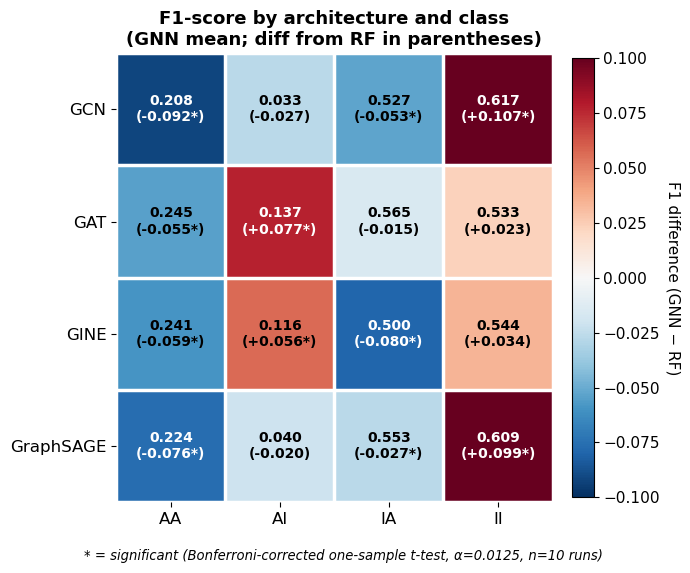

Saved: Figure3_F1_heatmap_key.png


In [17]:
fig, ax = plt.subplots(figsize=(7, 5.5))

mat = np.zeros((len(architectures), len(classes)))
annot = np.empty((len(architectures), len(classes)), dtype=object)
for i, arch in enumerate(architectures):
    for j, cls in enumerate(classes):
        row = per_class[(per_class.Architecture == arch) &
                         (per_class.Class == cls) &
                         (per_class.Metric == "f1")].iloc[0]
        mat[i, j] = row["diff"]
        star = "*" if row["significant_bonf"] else ""
        annot[i, j] = f"{row['GNN_mean']:.3f}\n({row['diff']:+.3f}{star})"

norm2 = TwoSlopeNorm(vmin=-0.10, vcenter=0, vmax=0.10)
im = ax.imshow(mat, cmap=cmap, norm=norm2, aspect="auto")
ax.set_xticks(range(len(classes)))
ax.set_xticklabels(classes, fontsize=12)
ax.set_yticks(range(len(architectures)))
ax.set_yticklabels(architectures, fontsize=12)
ax.set_title("F1-score by architecture and class\n(GNN mean; diff from RF in parentheses)", fontsize=13)

for i in range(len(architectures)):
    for j in range(len(classes)):
        ax.text(j, i, annot[i, j], ha="center", va="center", fontsize=10, fontweight="bold",
                 color="white" if abs(mat[i, j]) > 0.06 else "black")

for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(classes), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(architectures), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2.5)
ax.tick_params(which="minor", size=0)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("F1 difference (GNN \u2212 RF)", rotation=270, labelpad=15)

fig.text(0.5, -0.03, "* = significant (Bonferroni-corrected one-sample t-test, \u03b1=0.0125, n=10 runs)",
         ha="center", fontsize=9.5, style="italic")
fig.tight_layout()

fig.savefig("Figure3_F1_heatmap_key.png", dpi=220, bbox_inches="tight")
plt.show()
print("Saved: Figure3_F1_heatmap_key.png")

## 5. Figure 4 -- Per-class AUROC and AUPRC (GNN mean; difference from RF in parentheses)

AUROC and AUPRC use only how each model *ranks* molecules within a class, so they are threshold-independent. Chance level is
0.5 for AUROC but equals the class prevalence for AUPRC (about 0.05 for IA), so AUPRC must be read against that baseline.
Column labels show RF's value for each class.

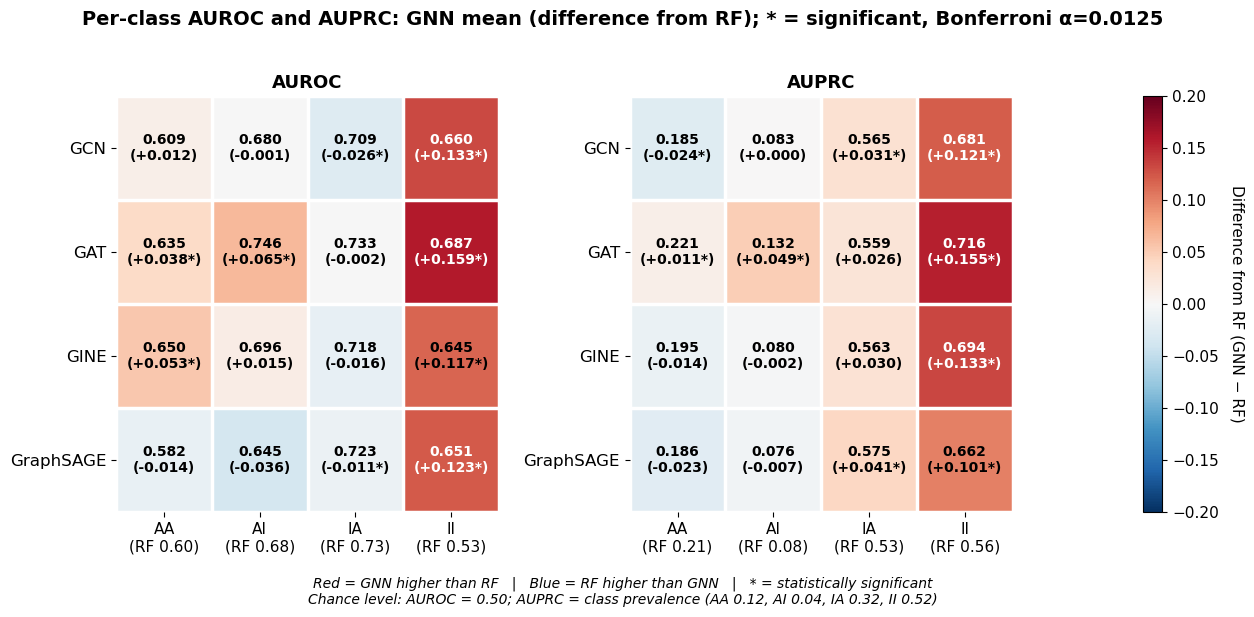

Saved: Figure4_AUC_per_class_heatmap.png


In [18]:
if HAVE_AUC:
    auc_pc = auc[auc.Class != "macro"]
    auc_metrics = ["AUROC", "AUPRC"]

    mats, annots, rf_ref = {}, {}, {}
    for metric in auc_metrics:
        m = np.zeros((len(architectures), len(classes)))
        a = np.empty((len(architectures), len(classes)), dtype=object)
        for i, arch in enumerate(architectures):
            for j, cls in enumerate(classes):
                row = auc_pc[(auc_pc.Architecture == arch) & (auc_pc.Class == cls) & (auc_pc.Metric == metric)].iloc[0]
                m[i, j] = row["diff"]
                star = "*" if row["significant_bonf"] else ""
                a[i, j] = f"{row['GNN_mean']:.3f}\n({row['diff']:+.3f}{star})"
                rf_ref[(metric, cls)] = row["RF"]
        mats[metric], annots[metric] = m, a

    # one symmetric colour scale shared by both panels so they are directly comparable
    vlim = max(0.10, np.ceil(max(np.abs(mats[m]).max() for m in auc_metrics) / 0.05) * 0.05)
    norm4 = TwoSlopeNorm(vmin=-vlim, vcenter=0, vmax=vlim)

    fig = plt.figure(figsize=(13.5, 5.4))
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.50)
    axes4 = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])]
    cax = fig.add_subplot(gs[0, 2])

    for ax, metric in zip(axes4, auc_metrics):
        mat = mats[metric]
        im = ax.imshow(mat, cmap=cmap, norm=norm4, aspect="auto")
        ax.set_xticks(range(len(classes)))
        ax.set_xticklabels([f"{c}\n(RF {rf_ref[(metric, c)]:.2f})" for c in classes], fontsize=11)
        ax.set_yticks(range(len(architectures))); ax.set_yticklabels(architectures, fontsize=12)
        ax.set_title(metric)
        for i in range(len(architectures)):
            for j in range(len(classes)):
                ax.text(j, i, annots[metric][i, j], ha="center", va="center", fontsize=10, fontweight="bold",
                        color="white" if abs(mat[i, j]) > 0.6 * vlim else "black")
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_xticks(np.arange(-0.5, len(classes), 1), minor=True)
        ax.set_yticks(np.arange(-0.5, len(architectures), 1), minor=True)
        ax.grid(which="minor", color="white", linewidth=2.5)
        ax.tick_params(which="minor", size=0)

    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label("Difference from RF (GNN \u2212 RF)", rotation=270, labelpad=18, fontsize=11)

    prevalence = ", ".join(f"{c} {SUPPORTS[c] / N_TEST:.2f}" for c in classes)
    fig.suptitle("Per-class AUROC and AUPRC: GNN mean (difference from RF); * = significant, Bonferroni \u03b1=0.0125",
                 fontsize=14, fontweight="bold", y=1.04)
    fig.text(0.5, -0.06,
             "Red = GNN higher than RF   |   Blue = RF higher than GNN   |   * = statistically significant\n"
             f"Chance level: AUROC = 0.50; AUPRC = class prevalence ({prevalence})",
             ha="center", fontsize=10, style="italic")

    fig.savefig("Figure4_AUC_per_class_heatmap.png", dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved: Figure4_AUC_per_class_heatmap.png")
else:
    print("Figure 4 skipped (no FINAL_auc_ttest_vs_RF.csv).")